In [1]:
import os
import random
import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score,confusion_matrix,classification_report,precision_score,recall_score,f1_score,roc_auc_score)
import matplotlib.pyplot as plt
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# PATHS

path2data = r"F:/Amrita_2024/DEEP LEARNING FOR SIGNAL & IMAGE _21AIE312/Python_neural network/"

path2train = r"F:/Amrita_2024/DEEP LEARNING FOR SIGNAL & IMAGE _21AIE312/Python_neural network/training_drion/"

path2labels = os.path.join(
    path2data,
    "drion_training.xlsx"
)

# READ EXCEL FILE
labels_df = pd.read_excel(path2labels)

print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print(labels_df.head())

print("\nDataset shape:")
print(labels_df.shape)

print("\nColumns:")
print(labels_df.columns.tolist())

print("\nClass distribution:")
print(labels_df["label"].value_counts())


DATASET INFORMATION
   ID        imgName  label
0   1  image_001.jpg      0
1   2  image_002.jpg      0
2   3  image_003.jpg      0
3   4  image_004.jpg      0
4   5  image_005.jpg      0

Dataset shape:
(86, 3)

Columns:
['ID', 'imgName', 'label']

Class distribution:
label
0    47
1    39
Name: count, dtype: int64


In [2]:
#  CHECK IMAGE FILES

image_paths = []
image_labels = []
image_names = []

print("\nChecking image files...")

for _, row in labels_df.iterrows():

    filename = str(row["imgName"])

    label = row["label"]

    image_path = os.path.join(
        path2train,
        filename
    )

    if os.path.exists(image_path):

        image_paths.append(image_path)
        image_labels.append(label)
        image_names.append(filename)

    else:

        print(
            "Image not found:",
            image_path
        )


print("\nTotal valid images:", len(image_paths))

# label mapping or label encoding.

unique_labels = sorted(
    list(set(image_labels))
)
print("\nOriginal classes:")
print(unique_labels)
#converts text labels into numbers.

label_to_index = {
    label: index
    for index, label in enumerate(unique_labels)
}
#This does the opposite.
index_to_label = {
    index: label
    for label, index in label_to_index.items()
}

print("\nLabel mapping:")
print(label_to_index)
#Convert all labels to numerical values
encoded_labels = np.array([
    label_to_index[label]
    for label in image_labels
])



Checking image files...

Total valid images: 86

Original classes:
[0, 1]

Label mapping:
{0: 0, 1: 1}


In [3]:
# TRAIN / TEST SPLIT
train_paths, test_paths, train_labels, test_labels = train_test_split(image_paths,encoded_labels,test_size=0.20,random_state=SEED,stratify=encoded_labels
)
print("\n" + "=" * 70)
print("TRAIN / TEST SPLIT")
print("=" * 70)
print(
    "Training images:",
    len(train_paths)
)
print(
    "Testing images :",
    len(test_paths)
)



TRAIN / TEST SPLIT
Training images: 68
Testing images : 18


In [4]:
# Transform
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("\nDevice:", device)

train_transform = transforms.Compose([transforms.Resize((96, 96)),

    # Mild augmentation
    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=10
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[ 0.485, 0.456, 0.406],std=[0.229,0.224,0.225])
])


test_transform = transforms.Compose([transforms.Resize((96, 96)),transforms.ToTensor(),

    transforms.Normalize(mean=[ 0.485, 0.456, 0.406],std=[0.229,0.224,0.225])
          
])




Device: cpu


In [5]:
class GlaucomaDataset(Dataset):

    def __init__(
        self,
        image_paths,
        labels,
        transform=None
    ):

        self.image_paths = image_paths

        self.labels = labels

        self.transform = transform


    def __len__(self):

        return len(
            self.image_paths
        )


    def __getitem__(self, index):

        image_path = self.image_paths[index]

        label = self.labels[index]

        # Read image
        image = Image.open(
            image_path
        ).convert("RGB")

        # Transform
        if self.transform is not None:

            image = self.transform(
                image
            )

        label = torch.tensor(
            label,
            dtype=torch.long
        )

        return image, label
test_dataset = GlaucomaDataset(test_paths,test_labels,transform=test_transform)


test_loader = DataLoader(test_dataset, batch_size=16,shuffle=False,num_workers=0)

In [6]:
def create_bootstrap_dataset(paths,labels):

    n_samples = len(paths)

    # Sampling WITH replacement

    indices = np.random.choice(n_samples,size=n_samples,replace=True)

    bootstrap_paths = [

        paths[i]

        for i in indices
    ]

    bootstrap_labels = [

        labels[i]

        for i in indices
    ]

    return (
        bootstrap_paths,
        np.array(bootstrap_labels)
    )



 # CREATE THREE BOOTSTRAP DATASETS

print("\n" + "=" * 70)
print("CREATING BOOTSTRAP DATASETS")
print("=" * 70)


bootstrap_paths_1, bootstrap_labels_1 = create_bootstrap_dataset(train_paths,train_labels)

bootstrap_paths_2, bootstrap_labels_2 = create_bootstrap_dataset(train_paths,train_labels)

bootstrap_paths_3, bootstrap_labels_3 = create_bootstrap_dataset(train_paths,train_labels)

print(
    "Bootstrap Dataset 1:",
    len(bootstrap_paths_1)
)
print(
    "Bootstrap Dataset 2:",
    len(bootstrap_paths_2)
)
print(
    "Bootstrap Dataset 3:",
    len(bootstrap_paths_3)
)




CREATING BOOTSTRAP DATASETS
Bootstrap Dataset 1: 68
Bootstrap Dataset 2: 68
Bootstrap Dataset 3: 68


In [7]:

#  CREATE THREE DATASETS

dataset1 = GlaucomaDataset(bootstrap_paths_1,bootstrap_labels_1,transform=train_transform)

dataset2 = GlaucomaDataset(bootstrap_paths_2,bootstrap_labels_2,transform=train_transform)

dataset3 = GlaucomaDataset(bootstrap_paths_3,bootstrap_labels_3,transform=train_transform)

test_dataset = GlaucomaDataset(test_paths,test_labels,transform=test_transform)

test_loader = DataLoader(test_dataset,batch_size=16, shuffle=False,num_workers=0)



In [8]:
# def create_bootstrap_dataset(paths,labels):

#     n_samples = len(paths)

#     # Sampling WITH replacement

#     indices = np.random.choice( n_samples,size=n_samples,replace=True)

#     bootstrap_paths = [

#         paths[i]

#         for i in indices
#     ]

#     bootstrap_labels = [

#         labels[i]

#         for i in indices
#     ]

#     return (
#         bootstrap_paths,
#         np.array(bootstrap_labels)
#     )


# # 13. CREATE THREE BOOTSTRAP DATASETS
# print("\n" + "=" * 70)
# print("CREATING BOOTSTRAP DATASETS")
# print("=" * 70)

# bootstrap_paths_1, bootstrap_labels_1 = create_bootstrap_dataset(train_paths,train_labels)
# bootstrap_paths_2, bootstrap_labels_2 = create_bootstrap_dataset(train_paths,train_labels)
# bootstrap_paths_3, bootstrap_labels_3 = create_bootstrap_dataset(train_paths,train_labels)

# print("Bootstrap Dataset 1:",len(bootstrap_paths_1))
# print("Bootstrap Dataset 2:",len(bootstrap_paths_2))
# print("Bootstrap Dataset 3:",len(bootstrap_paths_3))

# # 14. CREATE THREE DATASETS

# dataset1 = GlaucomaDataset(bootstrap_paths_1,bootstrap_labels_1,transform=train_transform)
# dataset2 = GlaucomaDataset(bootstrap_paths_2,bootstrap_labels_2,transform=train_transform)
# dataset3 = GlaucomaDataset(bootstrap_paths_3,bootstrap_labels_3,transform=train_transform)


In [9]:
# 15. CREATE DATALOADERS

loader1 = DataLoader(dataset1,batch_size=16,shuffle=True,num_workers=0)
loader2 = DataLoader(dataset2,batch_size=16,shuffle=True,num_workers=0)
loader3 = DataLoader(dataset3,batch_size=16,shuffle=True,num_workers=0)



In [10]:

# 16. CREATE CNN MODEL 1 - RESNET18
def create_resnet18():

    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

    num_features = model.fc.in_features

    model.fc = nn.Linear(num_features,2)

    return model

# CREATE CNN MODEL 2 - RESNET34

def create_resnet34():

    model = models.resnet34(weights=models.ResNet34_Weights.DEFAULT)

    num_features = model.fc.in_features

    model.fc = nn.Linear(num_features, 2)

    return model

# CREATE CNN MODEL 3 - DENSENET121

def create_densenet121():

    model = models.densenet121(
        weights=models.DenseNet121_Weights.DEFAULT)

    num_features = model.classifier.in_features

    model.classifier = nn.Linear(num_features,2)

    return model

# 19. CREATE THREE CNN MODELS

model1 = create_resnet18()

model2 = create_resnet34()

model3 = create_densenet121()


model1 = model1.to(device)
model2 = model2.to(device)
model3 = model3.to(device)

print("\n" + "=" * 70)
print("THREE CNN MODELS")
print("=" * 70)
print("CNN 1 : ResNet18")
print("CNN 2 : ResNet34")
print("CNN 3 : DenseNet121")



THREE CNN MODELS
CNN 1 : ResNet18
CNN 2 : ResNet34
CNN 3 : DenseNet121


In [11]:
#Loss function
criterion = nn.CrossEntropyLoss()

optimizer1 = torch.optim.Adam(model1.parameters(),lr=0.0001)

optimizer2 = torch.optim.Adam(model2.parameters(),lr=0.0001)


optimizer3 = torch.optim.Adam(model3.parameters(),lr=0.0001)



In [12]:
# ============================================================
# 22. TRAINING FUNCTION
# ============================================================

def train_model(model,dataloader,optimizer,criterion,epochs,model_name):

    print("\n")
    print("=" * 70)
    print(
        "TRAINING",
        model_name
    )
    print("=" * 70)

    model.train()

    for epoch in range(epochs):

        running_loss = 0.0

        correct = 0

        total = 0


        for images, labels in dataloader:

            images = images.to(device)

            labels = labels.to(device)

            optimizer.zero_grad()

            # Forward pass

            outputs = model(images)

            # Calculate loss

            loss = criterion(outputs,labels)

            # Backpropagation

            loss.backward()

            # Update weights

            optimizer.step()

            # Statistics

            running_loss += (loss.item()*images.size(0))

            _, predicted = torch.max(outputs,1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_loss = (running_loss / total)

        epoch_accuracy = (correct / total)
        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Loss: {epoch_loss:.4f} "
            f"Accuracy: {epoch_accuracy:.4f}"
        )


In [13]:
NUM_EPOCHS = 10
# 24. TRAIN CNN 1

train_model(model1,loader1, optimizer1,criterion, NUM_EPOCHS,"ResNet18")

# 25. TRAIN CNN 2

train_model(model2,loader2,optimizer2,criterion,NUM_EPOCHS, "ResNet34")

# 26. TRAIN CNN 3

train_model(model3,loader3,optimizer3,criterion,NUM_EPOCHS,"DenseNet121")




TRAINING ResNet18
Epoch [1/10] Loss: 0.6730 Accuracy: 0.6618
Epoch [2/10] Loss: 0.4663 Accuracy: 0.8235
Epoch [3/10] Loss: 0.5096 Accuracy: 0.8235
Epoch [4/10] Loss: 0.3443 Accuracy: 0.8382
Epoch [5/10] Loss: 0.2586 Accuracy: 0.8971
Epoch [6/10] Loss: 0.1641 Accuracy: 0.9706
Epoch [7/10] Loss: 0.1405 Accuracy: 0.9706
Epoch [8/10] Loss: 0.1968 Accuracy: 0.9265
Epoch [9/10] Loss: 0.0856 Accuracy: 0.9853
Epoch [10/10] Loss: 0.1747 Accuracy: 0.9412


TRAINING ResNet34
Epoch [1/10] Loss: 0.9066 Accuracy: 0.5735
Epoch [2/10] Loss: 0.7156 Accuracy: 0.6912
Epoch [3/10] Loss: 0.4151 Accuracy: 0.8088
Epoch [4/10] Loss: 0.5911 Accuracy: 0.7206
Epoch [5/10] Loss: 0.4089 Accuracy: 0.8382
Epoch [6/10] Loss: 0.3110 Accuracy: 0.8676
Epoch [7/10] Loss: 0.3574 Accuracy: 0.8235
Epoch [8/10] Loss: 0.2737 Accuracy: 0.8824
Epoch [9/10] Loss: 0.1916 Accuracy: 0.9412
Epoch [10/10] Loss: 0.0994 Accuracy: 0.9706


TRAINING DenseNet121
Epoch [1/10] Loss: 0.6703 Accuracy: 0.6029
Epoch [2/10] Loss: 0.6136 Accura

In [14]:
def get_predictions(model,dataloader):

    model.eval()

    predictions = []

    probabilities = []

    true_labels = []

    with torch.no_grad():

        for images, labels in dataloader:

            images = images.to(device)

            outputs = model(images)

            # Softmax probability

            probs = torch.softmax(outputs, dim=1)

            # Prediction

            _, predicted = torch.max(outputs,1)

            predictions.extend(predicted.cpu().numpy())
            # Probability of class 1
            probabilities.extend(probs[:, 1].cpu().numpy())
            true_labels.extend(labels.numpy()            )

    return (np.array(predictions),np.array(probabilities),np.array(true_labels))


In [15]:

# GET CNN 1 PREDICTIONS

pred1, prob1, y_true = get_predictions( model1,test_loader)

#  GET CNN 2 PREDICTIONS
pred2, prob2, _ = get_predictions(model2, test_loader)

# 30. GET CNN 3 PREDICTIONS

pred3, prob3, _ = get_predictions( model3, test_loader)


In [16]:

# MAJORITY VOTING

final_predictions = []

final_probabilities = []


for i in range(len(y_true)):

    votes = [pred1[i],pred2[i],pred3[i]]


    # Number of votes for class 0

    votes_0 = votes.count(0)


    # Number of votes for class 1

    votes_1 = votes.count(1)

    # Majority vote

    if votes_1 > votes_0:

        final_prediction = 1

    else:

        final_prediction = 0


    final_predictions.append(
        final_prediction
    )


    # Average probability

    average_probability = (prob1[i]+prob2[i]+prob3[i]) / 3.0

    final_probabilities.append(average_probability)


final_predictions = np.array(final_predictions)

final_probabilities = np.array(final_probabilities)


# METRIC FUNCTION

def calculate_metrics(y_true,y_pred,y_prob,model_name):

    accuracy = accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true,y_pred)
    tn, fp, fn, tp = cm.ravel()


    sensitivity = tp / (
        tp + fn
    ) if (tp + fn) != 0 else 0


    specificity = tn / (
        tn + fp
    ) if (tn + fp) != 0 else 0


    precision = precision_score(y_true,y_pred,zero_division=0)
    f1 = f1_score(y_true,y_pred,zero_division=0)
    auc = roc_auc_score(y_true,y_prob)
    print("\n")
    print("=" * 70)
    print(model_name)
    print("=" * 70)
    print("\nConfusion Matrix:")
    print(cm)
    print(f"\nAccuracy     : {accuracy:.4f}")

    print(f"Sensitivity  : {sensitivity:.4f}")

    print(f"Specificity  : {specificity:.4f}")

    print( f"Precision     : {precision:.4f}" )

    print(f"F1-score      : {f1:.4f}")

    print(f"AUC           : {auc:.4f}")


    return {"Model": model_name,"Accuracy": accuracy,"Sensitivity": sensitivity,"Specificity": specificity,"Precision": precision, "F1": f1,

        "AUC": auc

    }



In [17]:

# EVALUATE RESNET18
result1 = calculate_metrics(y_true,pred1,prob1,"ResNet18")

# 34. EVALUATE RESNET34

result2 = calculate_metrics( y_true, pred2, prob2,"ResNet34")

# EVALUATE DENSENET121

result3 = calculate_metrics( y_true, pred3, prob3,"DenseNet121")

# 36. EVALUATE BAGGING

result_bagging = calculate_metrics(y_true,final_predictions,final_probabilities,"3-CNN BAGGING")





ResNet18

Confusion Matrix:
[[8 2]
 [3 5]]

Accuracy     : 0.7222
Sensitivity  : 0.6250
Specificity  : 0.8000
Precision     : 0.7143
F1-score      : 0.6667
AUC           : 0.5875


ResNet34

Confusion Matrix:
[[6 4]
 [3 5]]

Accuracy     : 0.6111
Sensitivity  : 0.6250
Specificity  : 0.6000
Precision     : 0.5556
F1-score      : 0.5882
AUC           : 0.7125


DenseNet121

Confusion Matrix:
[[4 6]
 [5 3]]

Accuracy     : 0.3889
Sensitivity  : 0.3750
Specificity  : 0.4000
Precision     : 0.3333
F1-score      : 0.3529
AUC           : 0.4375


3-CNN BAGGING

Confusion Matrix:
[[6 4]
 [3 5]]

Accuracy     : 0.6111
Sensitivity  : 0.6250
Specificity  : 0.6000
Precision     : 0.5556
F1-score      : 0.5882
AUC           : 0.6125




MODEL PERFORMANCE COMPARISON
        Model  Accuracy  Sensitivity  Specificity  Precision       F1    AUC
     ResNet18  0.722222        0.625          0.8   0.714286 0.666667 0.5875
     ResNet34  0.611111        0.625          0.6   0.555556 0.588235 0.7125
  DenseNet121  0.388889        0.375          0.4   0.333333 0.352941 0.4375
3-CNN BAGGING  0.611111        0.625          0.6   0.555556 0.588235 0.6125


BAGGING CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.67      0.60      0.63        10
           1       0.56      0.62      0.59         8

    accuracy                           0.61        18
   macro avg       0.61      0.61      0.61        18
weighted avg       0.62      0.61      0.61        18



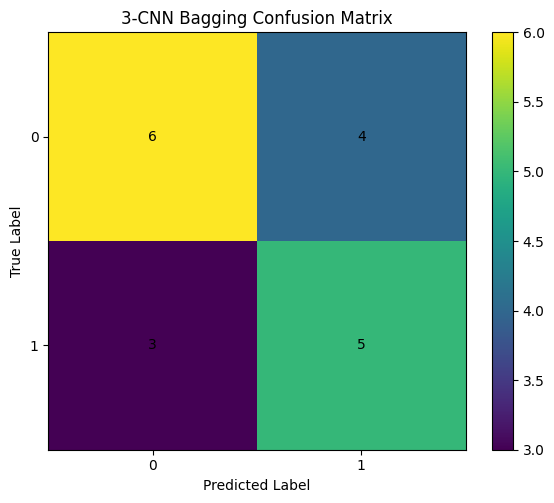

In [18]:

#  COMPARISON TABLE


results_df = pd.DataFrame([result1,result2,result3,result_bagging])

print("\n")
print("=" * 70)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 70)
print(results_df.to_string(index=False))


# CLASSIFICATION REPORT

print("\n")
print("=" * 70)
print("BAGGING CLASSIFICATION REPORT")
print("=" * 70)


print(
    classification_report(y_true,final_predictions,

        target_names=[
            str(index_to_label[0]),
            str(index_to_label[1])
        ],

        zero_division=0
    )
)


#  CONFUSION MATRIX

cm = confusion_matrix(y_true,final_predictions)
plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("3-CNN Bagging Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks([0, 1],
    [
     str(index_to_label[0]),
        str(index_to_label[1])
    ]
)


plt.yticks(
    [0, 1],
    [
        str(index_to_label[0]),
        str(index_to_label[1])
    ]
)


for i in range(2):

    for j in range(2):

        plt.text(j, i, cm[i, j],ha="center", va="center" )


plt.colorbar()

plt.tight_layout()

plt.show()




In [19]:

#  SAVE THREE CNN MODELS
torch.save(

    model1.state_dict(),

    os.path.join(
        path2data,
        "Bagging_ResNet18.pth"
    )
)


torch.save(

    model2.state_dict(),

    os.path.join(
        path2data,
        "Bagging_ResNet34.pth"
    )
)


torch.save(

    model3.state_dict(),

    os.path.join(
        path2data,
        "Bagging_DenseNet121.pth"
    )
)


# ============================================================
# 41. SAVE PREDICTIONS
# ============================================================

results_prediction = pd.DataFrame({

    "True_Label": [
        index_to_label[x]
        for x in y_true
    ],

    "ResNet18": [
        index_to_label[x]
        for x in pred1
    ],

    "ResNet34": [
        index_to_label[x]
        for x in pred2
    ],

    "DenseNet121": [
        index_to_label[x]
        for x in pred3
    ],

    "Bagging_Prediction": [
        index_to_label[x]
        for x in final_predictions
    ],

    "ResNet18_Probability": prob1,

    "ResNet34_Probability": prob2,

    "DenseNet121_Probability": prob3,

    "Bagging_Probability": final_probabilities
    })
output_file = os.path.join(path2data,"3_CNN_Bagging_Glaucoma_Results.xlsx")

results_prediction.to_excel(output_file,index=False)
print("\nPrediction results saved to:")

print(output_file)


# ============================================================
# 42. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 70)
print("FINAL BAGGING SUMMARY")
print("=" * 70)


print(
    "Dataset              : DRION Glaucoma"
)

print(
    "Number of CNNs       : 3"
)

print(
    "CNN 1                : ResNet18"
)

print(
    "CNN 2                : ResNet34"
)

print(
    "CNN 3                : DenseNet121"
)

print(
    "Sampling             : Bootstrap Sampling"
)

print(
    "Training              : Independent"
)

print(
    "Fusion                : Majority Voting"
)

print(
    f"Final Accuracy       : "
    f"{result_bagging['Accuracy']:.4f}"
)

print(
    f"Final Sensitivity    : "
    f"{result_bagging['Sensitivity']:.4f}"
)

print(
    f"Final Specificity    : "
    f"{result_bagging['Specificity']:.4f}"
)

print(
    f"Final Precision      : "
    f"{result_bagging['Precision']:.4f}"
)

print(
    f"Final F1-score       : "
    f"{result_bagging['F1']:.4f}"
)

print(
    f"Final AUC            : "
    f"{result_bagging['AUC']:.4f}"
)

print("=" * 70)


Prediction results saved to:
F:/Amrita_2024/DEEP LEARNING FOR SIGNAL & IMAGE _21AIE312/Python_neural network/3_CNN_Bagging_Glaucoma_Results.xlsx


FINAL BAGGING SUMMARY
Dataset              : DRION Glaucoma
Number of CNNs       : 3
CNN 1                : ResNet18
CNN 2                : ResNet34
CNN 3                : DenseNet121
Sampling             : Bootstrap Sampling
Training              : Independent
Fusion                : Majority Voting
Final Accuracy       : 0.6111
Final Sensitivity    : 0.6250
Final Specificity    : 0.6000
Final Precision      : 0.5556
Final F1-score       : 0.5882
Final AUC            : 0.6125
